In [ ]:
%pip install -q tensorflow matplotlib seaborn pandas scikit-learn
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.metrics import confusion_matrix
(x_train, y_train), (x_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)
print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)
class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
sample_no = 1002
plt.imshow(x_train[sample_no], cmap="gray")
plt.title(
    f"Ground Truth: {class_names[y_train[sample_no]]}"
)
plt.axis("off")
plt.show()
print("Class number:", y_train[sample_no])
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)
print("Training shape:", x_train.shape)
print("Testing shape :", x_test.shape)
model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),
    keras.layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),
    keras.layers.Flatten(),
    keras.layers.Dense(
        128,
        activation="relu"
    ),
    keras.layers.Dense(
        10,
        activation="softmax"
    )
])
model.summary()
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)
history_df = pd.DataFrame(history.history)
history_df[["loss", "val_loss"]].plot()
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()
predictions = model.predict(
    x_test[:5],
    verbose=0
)
predicted_classes = np.argmax(
    predictions,
    axis=1
)
print("Predicted:", predicted_classes)
print("Actual   :", y_test[:5])
for i in range(5):
    print(
        "Predicted:",
        class_names[predicted_classes[i]],
        "| Actual:",
        class_names[y_test[i]]
    )

all_predictions = model.predict(
    x_test,
    verbose=0
)
all_classes = np.argmax(
    all_predictions,
    axis=1
)
cm = confusion_matrix(
    y_test,
    all_classes
)
print(cm)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

### Downloading and preparing the Cats and Dogs dataset from Kaggle

In [ ]:
!pip install -q kagglehub
import kagglehub
import os
dataset_root_path = kagglehub.dataset_download("tongpython/cat-and-dog")
print(f"Path to downloaded dataset files: {dataset_root_path}")
print(f"Contents of {dataset_root_path}: {os.listdir(dataset_root_path)}")
train_data_path_check = os.path.join(dataset_root_path, 'training_set', 'training_set')
test_data_path_check = os.path.join(dataset_root_path, 'test_set', 'test_set')
if os.path.exists(train_data_path_check):
    print(f"Found training data at: {train_data_path_check}")
    print(f"Contents of {train_data_path_check}: {os.listdir(train_data_path_check)}")
else:
    print(f"Training data not found at expected path: {train_data_path_check}")
if os.path.exists(test_data_path_check):
    print(f"Found test data at: {test_data_path_check}")
    print(f"Contents of {test_data_path_check}: {os.listdir(test_data_path_check)}")
else:
    print(f"Test data not found at expected path: {test_data_path_check}")

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Path to downloaded dataset files: /kaggle/input/cat-and-dog
Contents of /kaggle/input/cat-and-dog: ['test_set', 'training_set']
Found training data at: /kaggle/input/cat-and-dog/training_set/training_set
Contents of /kaggle/input/cat-and-dog/training_set/training_set: ['dogs', 'cats']
Found test data at: /kaggle/input/cat-and-dog/test_set/test_set
Contents of /kaggle/input/cat-and-dog/test_set/test_set: ['dogs', 'cats']


Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Found 8005 files belonging to 2 classes.
Using 1601 files for validation.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - accuracy: 0.5787 - loss: 0.7141 - val_accuracy: 0.6758 - val_loss: 0.5974
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.6587 - loss: 0.6114 - val_accuracy: 0.6989 - val_loss: 0.5771
Epoch 3/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.7294 - loss: 0.5414 - val_accuracy: 0.7189 - val_loss: 0.5538
Epoch 4/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.7698 - loss: 0.4750 - val_accuracy: 0.7302 - val_loss: 0.5675
Epoch 5/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.8190 - loss: 0.3853 - val_accuracy: 0.7483 - val_loss: 0.5900
Epoch 6/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.8849 - loss: 0.2732 - val_accuracy: 0.7545 - val_loss: 0.6719
Epoch 7/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.9311 - loss: 0.1762 - val_accuracy: 0.7358 - val_loss: 0.9662
Epoch 8/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9666 - loss: 0.0966 -

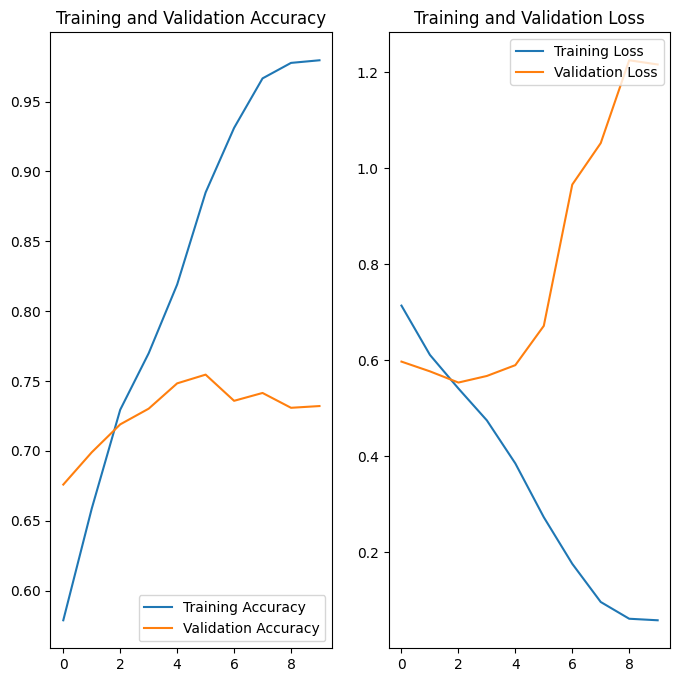

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
train_dir = '/kaggle/input/cat-and-dog/training_set/training_set'
test_dir = '/kaggle/input/cat-and-dog/test_set/test_set'
batch_size = 32
img_height = 150
img_width = 150
train_dataset = tf.keras.utils.image_dataset_from_directory(
  train_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)
val_dataset = tf.keras.utils.image_dataset_from_directory(
  train_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)
normalization_layer = layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y))
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 3)),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()
epochs = 10
history = model.fit(
  train_dataset,
  validation_data=val_dataset,
  epochs=epochs
)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(epochs)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()